# Statistics: 54 products

## Feature definitions

In [1]:
from pathlib import Path
import hashlib, json, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy import stats
from scipy.stats import norm, false_discovery_control
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT=Path.cwd()
CLEAN=ROOT/'artifacts/clean_market_data.parquet'
UNIVERSE=ROOT/'artifacts/research/liquidity_activity/final_54/selected_54_universe.json'
OUT=ROOT/'artifacts/research_54/statistics'
FEATURES=OUT/'features'
for p in [OUT, FEATURES, OUT/'figures']: p.mkdir(parents=True,exist_ok=True)
START=pd.Timestamp('2016-01-01'); SPLIT=pd.Timestamp('2020-01-01'); END=pd.Timestamp('2022-01-01')
LAGS=[1,2,3,5,10,15,30,60,120]
PERIODS=['train','test','full']
RAW_FIELDS={'open':'Open','high':'High','low':'Low','close':'Close','volume':'Volume','money':'Turnover','open_interest':'Open interest'}
BASE_FEATURES=[*RAW_FIELDS,'log_return','simple_return','bar_range','rolling_30m_volatility','log1p_volume','log1p_turnover','normalized_return']
def digest(path):
    with Path(path).open('rb') as stream: return hashlib.file_digest(stream,'sha256').hexdigest()
universe=json.loads(UNIVERSE.read_text())
files=universe['instruments']
assert len(files)==len(set(files))==54
source_hash=digest(CLEAN)
assert source_hash==universe['source_sha256'], 'Input changed: rebuild Notebook 4 first'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':120})
COLORS={'train':'#25638c','test':'#c17229','full':'#52765c'}
def show(df,title,rows=15):
    display(df.head(rows).style.hide(axis='index').format(precision=5,na_rep='NA').set_caption(title))
    if len(df)>rows: print(f"Showing {rows}/{len(df)} rows; the complete CSV is saved.")
def savefig(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight'); plt.show()
review=pd.DataFrame([
 ('0–4',"Inputs and features","Definitions preserved; scope restricted to 54 files and 2016–2021."),
 ('5–13',"Segments, moments and audit","Boundaries, exact lags, zero volumes and extremes checked; constant inputs return NaN."),
 ('14–19',"Construction and coverage","Per-file Parquet, summaries and reconciliation with notebook 02 features."),
 ('20–44',"Correlation API","Exact positions and lag interpretation preserved; pooled ACF and equal-segment mean remain separate."),
 ('45–57','13×13 screen, HAC, BY',"Original tests concern mean estimated segment coefficients. New HAC concerns pooled Pearson; p-values are recalculated only for the explicit ACF tests."),
 ('58–61',"Interpretation","Price/OI persistence and overlapping rolling volatility do not establish sign predictability."),
 ('62–63',"Validation and lineage","Boundary, return, direct-Pearson, numerical-derivative and source-hash checks.")
],columns=["Notebook 02 cells (zero-based)","Block","Finding / action"])
review.to_csv(OUT/'notebook02_review.csv',index=False)
show(review,"Review of every notebook 02 block")
print("54 files; source SHA-256:",source_hash)

Notebook 02 cells (zero-based),Block,Finding / action
0–4,Inputs and features,Definitions preserved; scope restricted to 54 files and 2016–2021.
5–13,"Segments, moments and audit","Boundaries, exact lags, zero volumes and extremes checked; constant inputs return NaN."
14–19,Construction and coverage,"Per-file Parquet, summaries and reconciliation with notebook 02 features."
20–44,Correlation API,Exact positions and lag interpretation preserved; pooled ACF and equal-segment mean remain separate.
45–57,"13×13 screen, HAC, BY",Original tests concern mean estimated segment coefficients. New HAC concerns pooled Pearson; p-values are recalculated only for the explicit ACF tests.
58–61,Interpretation,Price/OI persistence and overlapping rolling volatility do not establish sign predictability.
62–63,Validation and lineage,"Boundary, return, direct-Pearson, numerical-derivative and source-hash checks."


54 files; source SHA-256: 06f0144a97dacd0d186a6fcca3ce394f715fd2489a26ffc74a93d1e105b60988


## Features and boundaries

In [2]:
def safe_log1p(values):
    result = pd.Series(np.nan, index=values.index, dtype=float)
    defined = np.isfinite(values) & values.gt(-1)
    result.loc[defined] = np.log1p(values.loc[defined])
    return result

def build_segment_features(cleaned):
    """Stable chronological runs of one symbol, with exactly 60 s between bars.

    NaNs in prices do not delete rows or split a time-continuous run. Undefined
    features stay NaN; rolling windows need 30 observed returns in that run.
    """
    required = {"ID", "date", "symbol", *RAW_FIELDS}
    missing = required - set(cleaned.columns)
    if missing:
        raise ValueError(f"Missing input columns: {sorted(missing)}")
    bars = cleaned.copy()
    bars["date"] = pd.to_datetime(bars.date, errors="raise")
    bars = bars.sort_values(["date", "ID"], kind="stable", na_position="last").reset_index(drop=True)
    if bars.empty:
        raise ValueError("Empty input: no bars to segment")
    delta = bars.date.diff()
    same_symbol = bars.symbol.eq(bars.symbol.shift()) & bars.symbol.notna() & bars.symbol.shift().notna()
    aligned = bars.date.notna() & bars.date.eq(bars.date.dt.floor("min"))
    ambiguous_time = bars.date.duplicated(keep=False) & bars.date.notna()
    continuous = (
        delta.eq(pd.Timedelta(minutes=1)) & same_symbol
        & aligned & aligned.shift(fill_value=False)
        & ~ambiguous_time & ~ambiguous_time.shift(fill_value=False)
    ).fillna(False)
    bars["segment_id"] = (~continuous).cumsum().astype("int64")
    bars["segment_start"] = ~continuous
    bars["delta_minutes"] = delta.dt.total_seconds() / 60
    previous_close = bars.close.shift()
    usable_price_pair = (
        continuous & np.isfinite(bars.close) & np.isfinite(previous_close)
        & bars.close.gt(0) & previous_close.gt(0)
    )
    bars["simple_return"] = np.nan
    bars["log_return"] = np.nan
    bars.loc[usable_price_pair, "simple_return"] = (
        bars.loc[usable_price_pair, "close"] / previous_close.loc[usable_price_pair] - 1
    )
    bars.loc[usable_price_pair, "log_return"] = (
        np.log(bars.loc[usable_price_pair, "close"]) - np.log(previous_close.loc[usable_price_pair])
    )
    bars["bar_range"] = bars.high - bars.low
    rolling = bars.groupby("segment_id", sort=False).log_return.rolling(
        window=30, min_periods=30,
    ).std(ddof=1)
    bars["rolling_30m_volatility"] = rolling.droplevel(0).reindex(bars.index)
    bars["log1p_volume"] = safe_log1p(bars.volume)
    bars["log1p_turnover"] = safe_log1p(bars.money)
    return bars

## ACF and uncertainty

In [3]:
def hac_scores(scores,denominator,active_dates,min_dates=90):
    scores=np.asarray(scores,float)
    result={}
    for bandwidth in [20,60]:
        b=min(bandwidth,len(scores)-1)
        meat=np.sum(scores*scores)
        for lag in range(1,b+1): meat+=2*(1-lag/(b+1))*np.sum(scores[lag:]*scores[:-lag])
        se=np.sqrt(max(0.,meat)*active_dates/max(1,active_dates-1))/max(1,denominator)
        result[f'se_hac{bandwidth}']=se if active_dates>=min_dates and se>0 else np.nan
    return result

def acf_row(values,segments,days,lag,allowed=None):
    x=values[lag:]; y=values[:-lag]
    valid=(segments[lag:]==segments[:-lag])&np.isfinite(x)&np.isfinite(y)
    if allowed is not None: valid &= allowed[lag:]&allowed[:-lag]
    a=x[valid]; b=y[valid]; group=segments[lag:][valid]; day=days[lag:][valid]
    n=len(a); D=int(days.max())+1 if len(days) else 0
    result=dict(pairs=n,dates_with_pairs=len(np.unique(day)),acf=np.nan,segment_mean=np.nan,defined_segments=0,
                se_hac20=np.nan,se_hac60=np.nan,se=np.nan,ci95_low=np.nan,ci95_high=np.nan,p=np.nan)
    if n<3 or np.ptp(a)==0 or np.ptp(b)==0: return result
    a=a-a.mean(); b=b-b.mean()
    u=a/np.sqrt(np.mean(a*a)); v=b/np.sqrt(np.mean(b*b))
    rho=float(np.clip(np.mean(u*v),-1,1)); result['acf']=rho
    influence=u*v-.5*rho*(u*u+v*v)
    scores=np.bincount(day,weights=influence,minlength=D)
    result.update(hac_scores(scores,n,result['dates_with_pairs']))
    result['se']=float(np.max([result['se_hac20'],result['se_hac60']]))
    if np.isfinite(result['se']):
        result.update(ci95_low=rho-1.96*result['se'],ci95_high=rho+1.96*result['se'],p=2*norm.sf(abs(rho/result['se'])))
    # Equal weights for defined segment coefficients; no concatenation across gaps.
    _,first,g=np.unique(group,return_index=True,return_inverse=True); size=g.max()+1
    count=np.bincount(g,minlength=size)
    # Remove a group reference first so constant segment pairs stay exactly constant.
    ga=a-a[first][g]; gb=b-b[first][g]
    ma=np.bincount(g,weights=ga,minlength=size)/count
    mb=np.bincount(g,weights=gb,minlength=size)/count
    aa=ga-ma[g]; bb=gb-mb[g]
    xx=np.bincount(g,weights=aa*aa,minlength=size); yy=np.bincount(g,weights=bb*bb,minlength=size)
    xy=np.bincount(g,weights=aa*bb,minlength=size); den=np.sqrt(xx*yy)
    ok=(count>=2)&(den>0)
    coefficients=xy[ok]/den[ok]
    result['segment_mean']=float(np.mean(coefficients)) if len(coefficients) else np.nan
    result['defined_segments']=int(ok.sum())
    return result

def moments(values):
    a=np.asarray(values,float); x=a[np.isfinite(a)]; n=len(x)
    result=dict(n=n,missing=len(a)-n,mean=np.nan,std=np.nan,skew=np.nan,excess_kurtosis=np.nan,zero_share=np.nan,min=np.nan,max=np.nan)
    if not n: return result
    result.update(mean=x.mean(),std=x.std(ddof=1) if n>1 else np.nan,zero_share=np.mean(x==0),min=x.min(),max=x.max())
    for q in [.001,.01,.05,.5,.95,.99,.999]: result[f'q{q:g}']=np.quantile(x,q)
    if n>3 and np.ptp(x)>0: result.update(skew=stats.skew(x,bias=False),excess_kurtosis=stats.kurtosis(x,fisher=True,bias=False))
    return result

def tail_metrics(values):
    result=moments(values); x=np.asarray(values,float); x=x[np.isfinite(x)]
    sd=result['std']
    for k in [3,5,10]:
        count=int((np.abs((x-result['mean'])/sd)>k).sum()) if len(x) and sd>0 else 0
        probability=count/len(x) if len(x) and sd>0 else np.nan
        result.update({f'tail_{k}sigma_count':count,f'tail_{k}sigma_probability':probability,
                       f'tail_{k}sigma_vs_gaussian':probability/(2*norm.sf(k))})
    result['tail_label']='heavier_than_gaussian' if result['excess_kurtosis']>0 and result['tail_3sigma_vs_gaussian']>1 else 'mixed_or_undefined'
    return result

## Formula checks

In [4]:
probe=np.array([np.nan,.2,.1,np.nan,-.1,.3,.4,.2,.1]); seg=np.array([1,1,1,1,2,2,2,2,2]); days=np.zeros(len(probe),int)
for lag in [1,2,3]:
    out=acf_row(probe,seg,days,lag)
    ok=(seg[lag:]==seg[:-lag])&np.isfinite(probe[lag:])&np.isfinite(probe[:-lag])
    assert out['pairs']==ok.sum()
    if ok.sum()>=3:
        np.testing.assert_allclose(out['acf'],np.corrcoef(probe[lag:][ok],probe[:-lag][ok])[0,1],atol=1e-14)
rng=np.random.default_rng(42); x=rng.normal(size=100); y=.3*x+rng.normal(size=100)
u=(x-x.mean())/x.std(); v=(y-y.mean())/y.std(); rho=np.mean(u*v)
score=u*v-.5*rho*(u*u+v*v)
def weighted_corr(w):
    w=w/w.sum(); a=x-np.sum(w*x); b=y-np.sum(w*y)
    return np.sum(w*a*b)/np.sqrt(np.sum(w*a*a)*np.sum(w*b*b))
w=np.ones(100); step=1e-5
for i in [0,17,91]:
    wp=w.copy(); wm=w.copy(); wp[i]+=step; wm[i]-=step
    np.testing.assert_allclose((weighted_corr(wp)-weighted_corr(wm))/(2*step),score[i]/100,atol=1e-10)
np.testing.assert_allclose(moments(x)['excess_kurtosis'],pd.Series(x).kurt(),atol=1e-12)
assert np.isnan(moments(np.ones(10))['excess_kurtosis'])
print("Exact lags, Pearson, weighting effects and Fisher excess kurtosis checked.")
constant_runs=np.r_[np.full(21,.1),np.full(21,.2)]
constant_segments=np.r_[np.ones(21,int),np.full(21,2)]
assert acf_row(constant_runs,constant_segments,np.zeros(42,int),1)['defined_segments']==0


Exact lags, Pearson, weighting effects and Fisher excess kurtosis checked.


## Build by instrument

In [5]:
coverage_rows=[]; moment_rows=[]; acf_rows=[]; tail_rows=[]; curves=[]; yearly=[]; outliers=[]; daily_parts=[]; feature_records=[]; profile_parts=[]; legacy_checks=[]
started=time.monotonic()
tail_grid=np.r_[np.linspace(.1,3,30),np.linspace(3.25,10,28)]
with threadpool_limits(limits=1):
    for number,filename in enumerate(files,1):
        clean=pd.read_parquet(CLEAN,filters=[('instrument','=',filename),('date','>=',START),('date','<',END)])
        bars=build_segment_features(clean)
        bars['normalized_return']=(bars.simple_return/bars.rolling_30m_volatility.where(bars.rolling_30m_volatility>0)).replace([np.inf,-np.inf],np.nan)
        past_scale=bars.groupby('segment_id',sort=False).rolling_30m_volatility.shift(1)
        bars['causal_standardized_return']=(bars.log_return/past_scale.where(past_scale>0)).replace([np.inf,-np.inf],np.nan)
        train=bars.date<SPLIT
        bars['period']=np.where(train,'train','test')
        clock=bars.date.dt.hour*60+bars.date.dt.minute
        center=bars.loc[train,'log_return'].abs().mean()
        profile=pd.DataFrame({'minute':clock[train],'absolute':bars.loc[train,'log_return'].abs()}).groupby('minute').absolute.agg(['sum','count'])
        profile['factor']=(profile['sum']+20*center)/(profile['count']+20)/center
        known=profile['count']>=20
        profile.loc[~known,'factor']=1.
        factor=clock.map(profile.factor).fillna(1.)
        bars['seasonal_factor_train']=factor
        bars['seasonal_profile_known']=clock.isin(profile.index[known])
        bars['deseasonalized_log_return']=bars.log_return/factor
        profile_parts.append(profile.reset_index().assign(file=filename))
        inside=~bars.segment_start
        assert bars.loc[inside,'date'].sub(bars.date.shift()[inside]).eq(pd.Timedelta(minutes=1)).all()
        assert bars.loc[inside,'symbol'].eq(bars.symbol.shift()[inside]).all()
        assert bars.loc[bars.segment_start,['simple_return','log_return','rolling_30m_volatility']].isna().all().all()
        assert len(bars)==len(clean)
        valid=bars.log_return.notna()
        np.testing.assert_allclose(np.expm1(bars.loc[valid,'log_return']),bars.loc[valid,'simple_return'],atol=1e-12,rtol=1e-9)
        # Reconcile every rebuilt base feature against Notebook 2's stored values by source ID.
        old=pd.read_parquet(ROOT/'artifacts/research_features.parquet',filters=[('instrument','=',filename),('date','>=',START),('date','<',END)],
                            columns=['ID','date',*BASE_FEATURES]).sort_values(['date','ID'],kind='stable').reset_index(drop=True)
        np.testing.assert_array_equal(old.ID,bars.ID)
        for field in BASE_FEATURES:
            np.testing.assert_allclose(old[field],bars[field],equal_nan=True,atol=1e-12,rtol=1e-9)
        legacy_checks.append(dict(file=filename,rows=len(bars),fields=len(BASE_FEATURES),matches=True))
        path=FEATURES/(Path(filename).stem+'.parquet')
        temporary=path.with_suffix('.tmp.parquet')
        bars.to_parquet(temporary,index=False,compression='zstd'); temporary.replace(path)
        feature_records.append(dict(file=filename,path=str(path.relative_to(ROOT)),sha256=digest(path),rows=len(bars)))
        ids=bars.segment_id.to_numpy(); lr=bars.log_return.to_numpy(); sr=bars.simple_return.to_numpy()
        for period in PERIODS:
            mask=(bars.period.eq(period).to_numpy() if period!='full' else np.ones(len(bars),bool))
            part=bars.loc[mask]; s=ids[mask]; dayvalues=part.date.dt.normalize()
            _,d=np.unique(dayvalues.to_numpy(),return_inverse=True)
            vol=part.volume.to_numpy(); finitevol=np.isfinite(vol)&(vol>=0)
            lengths=part.groupby('segment_id',sort=False).size()
            coverage_rows.append(dict(file=filename,period=period,rows=len(part),dates=len(np.unique(d)),start=part.date.min(),end=part.date.max(),
                segments=len(lengths),median_segment_bars=lengths.median(),short_segments=int((lengths<31).sum()),
                returns=int(part.log_return.notna().sum()),unknown_returns=int(part.log_return.isna().sum()),
                zero_volume_pct=100*np.sum(vol==0)/finitevol.sum(),known_volume_bars=int(finitevol.sum()),
                seasonal_unknown_pct=100*(~part.seasonal_profile_known).mean()))
            for field in BASE_FEATURES+['causal_standardized_return']:
                moment_rows.append(dict(file=filename,period=period,feature=field,**moments(part[field])))
            series={'log_return':lr[mask],'abs_log_return':np.abs(lr[mask]),'simple_return':sr[mask],
                    'abs_simple_return':np.abs(sr[mask]),'squared_log_return':lr[mask]**2,
                    'abs_deseasonalized_log_return':np.abs(part.deseasonalized_log_return.to_numpy())}
            for name,values in series.items():
                for lag in LAGS:
                    acf_rows.append(dict(file=filename,period=period,series=name,lag=lag,sample='all',**acf_row(values,s,d,lag)))
            for name in ['log_return','abs_log_return']:
                for lag in [1,5,30]:
                    acf_rows.append(dict(file=filename,period=period,series=name,lag=lag,sample='positive_volume_pairs',**acf_row(series[name],s,d,lag,vol>0)))
            for field in ['log_return','simple_return','causal_standardized_return']:
                values=part[field].to_numpy()
                for group,choose in [('all',np.ones(len(part),bool)),('positive_volume',vol>0),('zero_volume',vol==0)]:
                    tail_rows.append(dict(file=filename,period=period,return_type=field,volume_group=group,**tail_metrics(values[choose])))
            r=lr[mask]; r=r[np.isfinite(r)]; z=np.sort(np.abs((r-r.mean())/r.std(ddof=1)))
            for threshold,p in zip(tail_grid,(len(z)-np.searchsorted(z,tail_grid,side='right'))/len(z)):
                curves.append(dict(file=filename,period=period,threshold_sigma=threshold,probability=p))
        for year,part in bars.groupby(bars.date.dt.year):
            yearly.append(dict(file=filename,year=int(year),**tail_metrics(part.log_return)))
        ix=np.argsort(np.where(np.isfinite(lr),np.abs(lr),-1))[-5:]
        extremes=bars.loc[ix,['instrument','ID','date','symbol','segment_id','close','volume','log_return','simple_return']].copy()
        extremes['previous_close']=bars.close.shift().iloc[ix].to_numpy(); outliers.append(extremes)
        daily=bars.assign(day=bars.date.dt.normalize(),r2=bars.log_return**2).groupby('day').agg(rms2=('r2','mean'),returns=('log_return','count'),zero_volume=('volume',lambda s:s.eq(0).mean()))
        daily['rms']=np.sqrt(daily.rms2); daily['train_std']=bars.loc[train,'log_return'].std(); daily_parts.append(daily.reset_index().assign(file=filename))
        if number%6==0 or number==54: print(f"{number}/54: features, ACF and tails; {time.monotonic()-started:.0f} s",flush=True)
coverage=pd.DataFrame(coverage_rows); description=pd.DataFrame(moment_rows); acf=pd.DataFrame(acf_rows); tails=pd.DataFrame(tail_rows)
tail_curves=pd.DataFrame(curves); annual=pd.DataFrame(yearly); daily=pd.concat(daily_parts,ignore_index=True)
acf['q_by']=np.nan
for period,ix in acf.groupby('period').groups.items():
    ps=acf.loc[ix,'p']; adjusted=false_discovery_control(ps.fillna(1).to_numpy(),method='by')
    acf.loc[ix,'q_by']=np.where(ps.notna(),adjusted,np.nan)
acf['significant']=acf.q_by<.05
for name,table in {'coverage':coverage,'feature_statistics':description,'acf':acf,'tails':tails,'annual_tails':annual,'tail_curves':tail_curves,
                   'largest_absolute_returns':pd.concat(outliers),'seasonal_profiles_train':pd.concat(profile_parts),'legacy_feature_reconciliation':pd.DataFrame(legacy_checks)}.items():
    table.to_csv(OUT/(name+'.csv'),index=False)
daily.to_parquet(OUT/'daily_volatility.parquet',index=False)
assert set(coverage.file)==set(files) and len(coverage)==54*3
print("Reconciled with notebook 02:",len(legacy_checks),"files; original feature definitions preserved.")

6/54: features, ACF and tails; 26 s


12/54: features, ACF and tails; 56 s


18/54: features, ACF and tails; 83 s


24/54: features, ACF and tails; 106 s


30/54: features, ACF and tails; 128 s


36/54: features, ACF and tails; 149 s


42/54: features, ACF and tails; 169 s


48/54: features, ACF and tails; 188 s


54/54: features, ACF and tails; 207 s


Reconciled with notebook 02: 54 files; original feature definitions preserved.


## Coverage and ACF

period,files,bars,returns,start,end
train,54,15067695,14912832,2016-01-04 09:01:00,2019-12-31 15:15:00
test,54,7671030,7587843,2020-01-02 09:01:00,2021-10-18 15:15:00
full,54,22738725,22500675,2016-01-04 09:01:00,2021-10-18 15:15:00


file,dates,rows,start,end
SA9999.XZCE.csv,19,6330,2019-12-05 21:01:00,2019-12-31 15:00:00
EB9999.XDCE.csv,64,21840,2019-09-26 09:01:00,2019-12-31 15:00:00
SS9999.XSGE.csv,79,29985,2019-09-24 21:01:00,2019-12-31 15:00:00


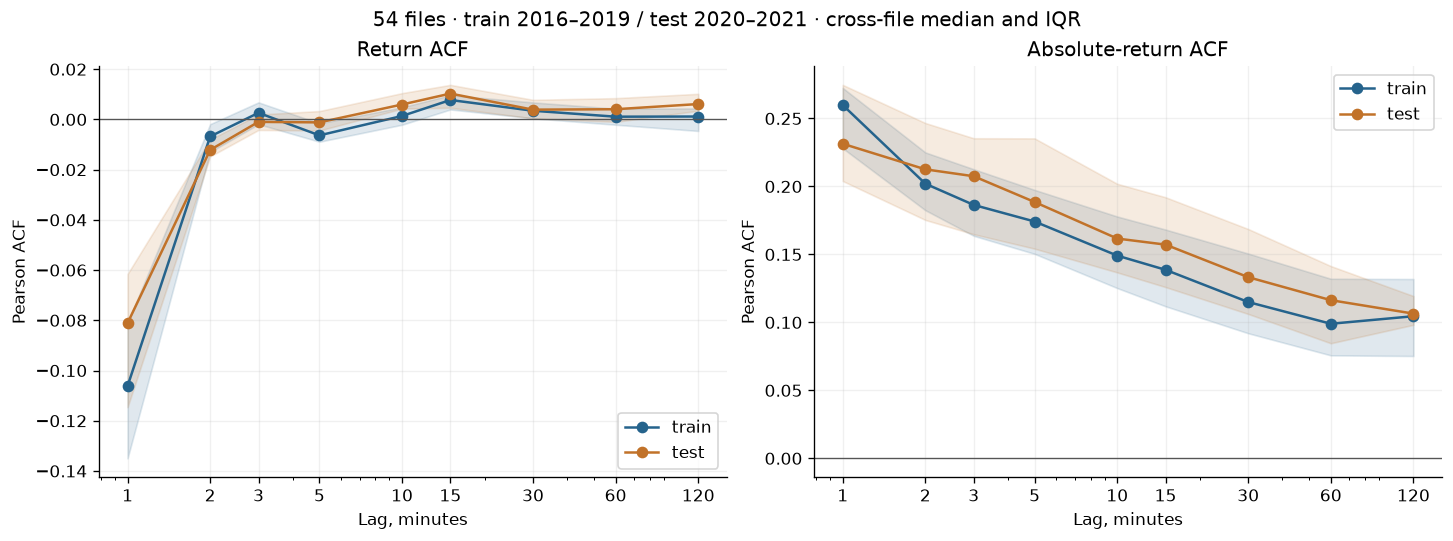

In [6]:
show(coverage.groupby('period',sort=False).agg(files=('file','nunique'),bars=('rows','sum'),returns=('returns','sum'),start=('start','min'),end=('end','max')).reset_index(),"Observed coverage")
short=coverage.query("period=='train' and dates<90")
show(short[['file','dates','rows','start','end']],"Insufficient training dates for HAC (minimum 90)")
fig,axes=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
for ax,series,title in zip(axes,['log_return','abs_log_return'],["Return ACF","Absolute-return ACF"]):
    for period in ['train','test']:
        p=acf.query('series==@series and period==@period and sample=="all"').groupby('lag').acf
        med=p.median().reindex(LAGS); low=p.quantile(.25).reindex(LAGS); high=p.quantile(.75).reindex(LAGS)
        ax.plot(LAGS,med,marker='o',color=COLORS[period],label=period)
        ax.fill_between(LAGS,low,high,alpha=.14,color=COLORS[period])
    ax.axhline(0,color='#555',lw=.8); ax.set(xscale='log',title=title,xlabel="Lag, minutes",ylabel='Pearson ACF')
    ax.set_xticks(LAGS,labels=LAGS); ax.legend()
fig.suptitle("54 files · train 2016–2019 / test 2020–2021 · cross-file median and IQR")
savefig(fig,'acf_profiles')

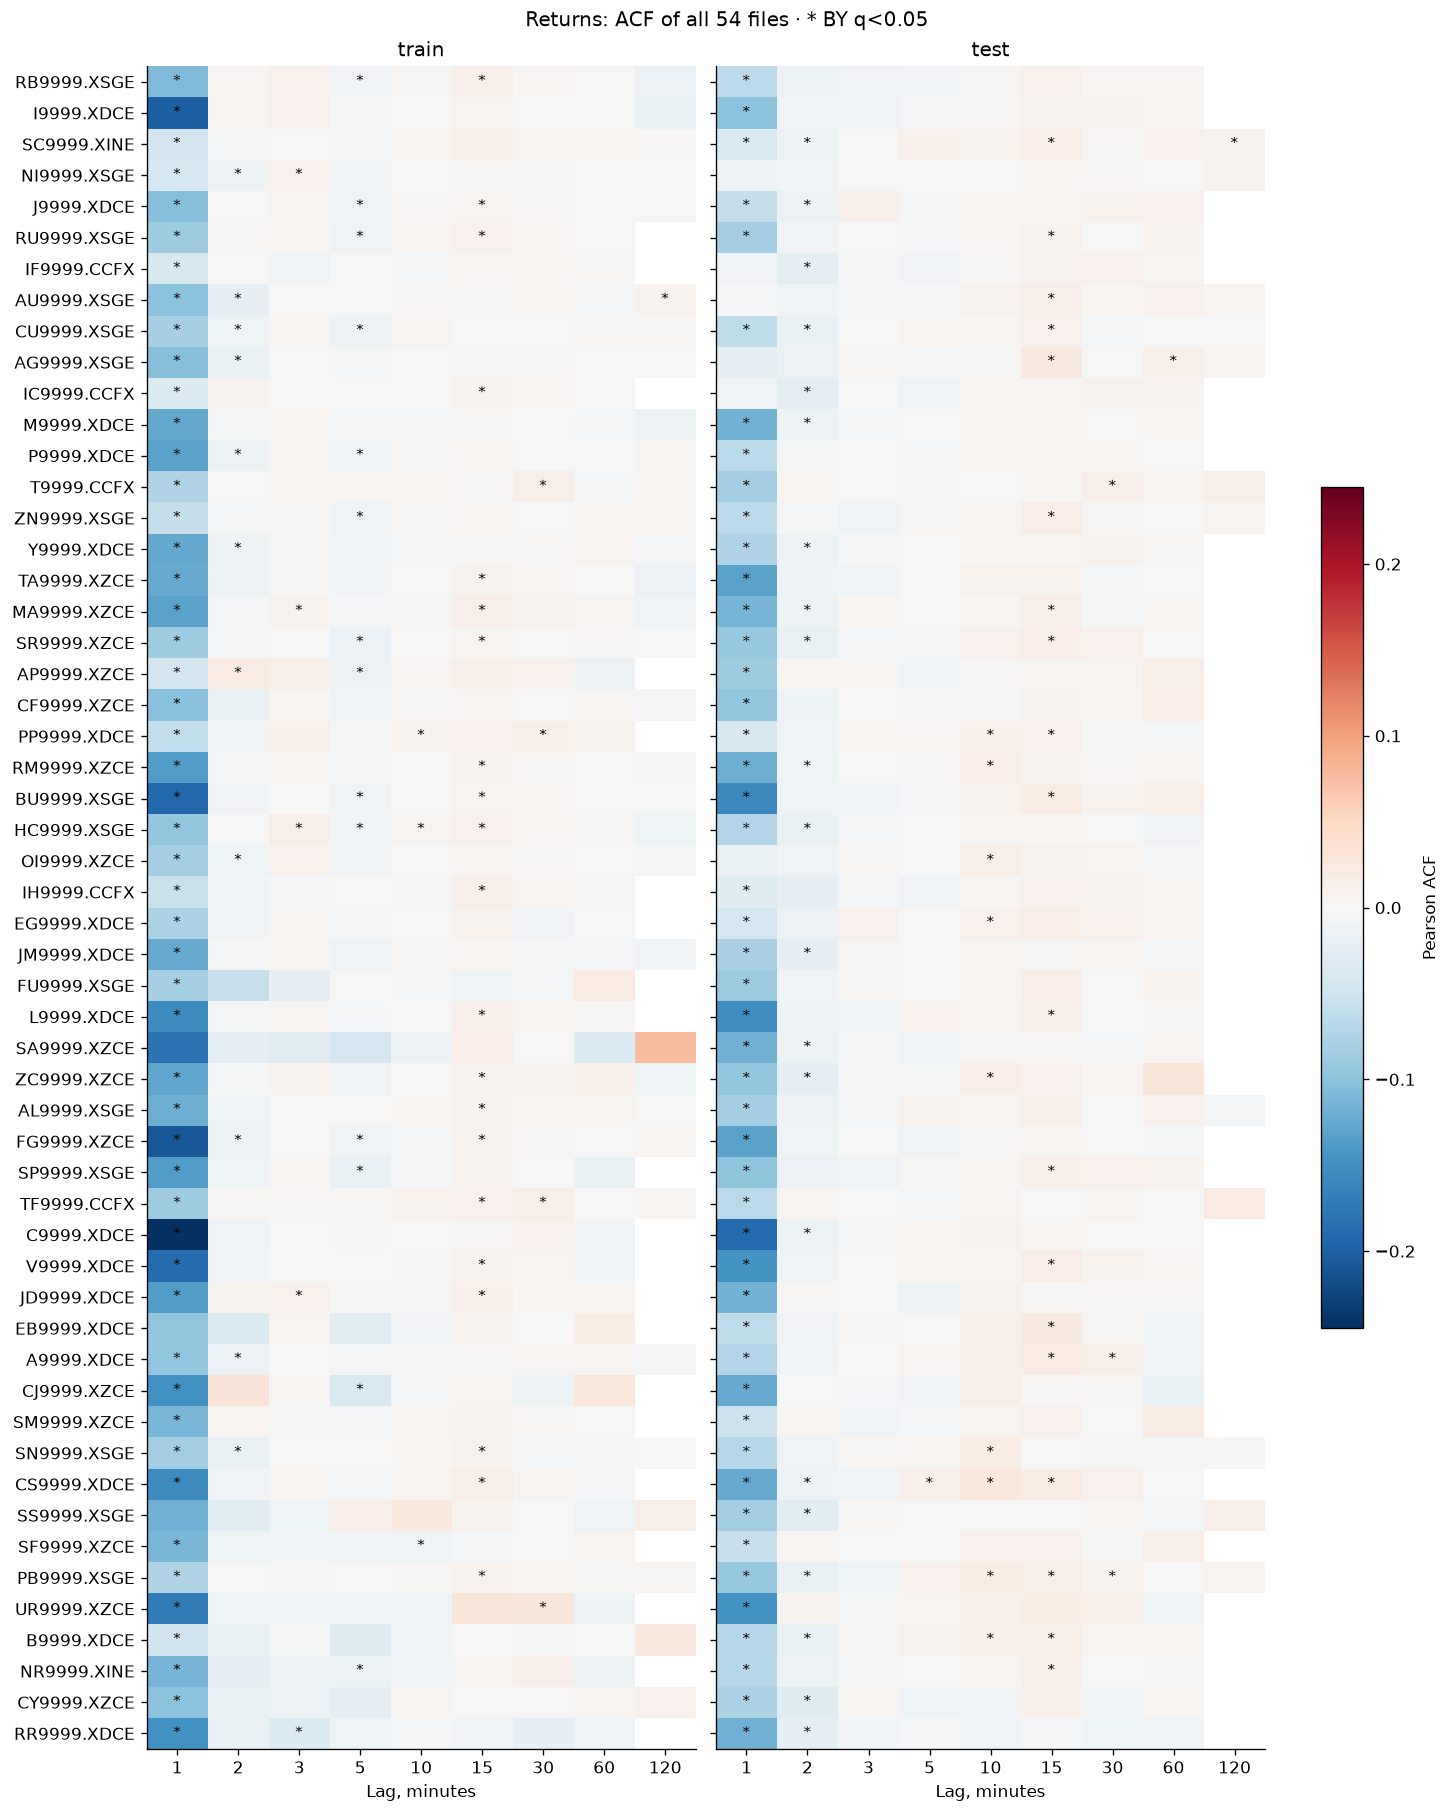

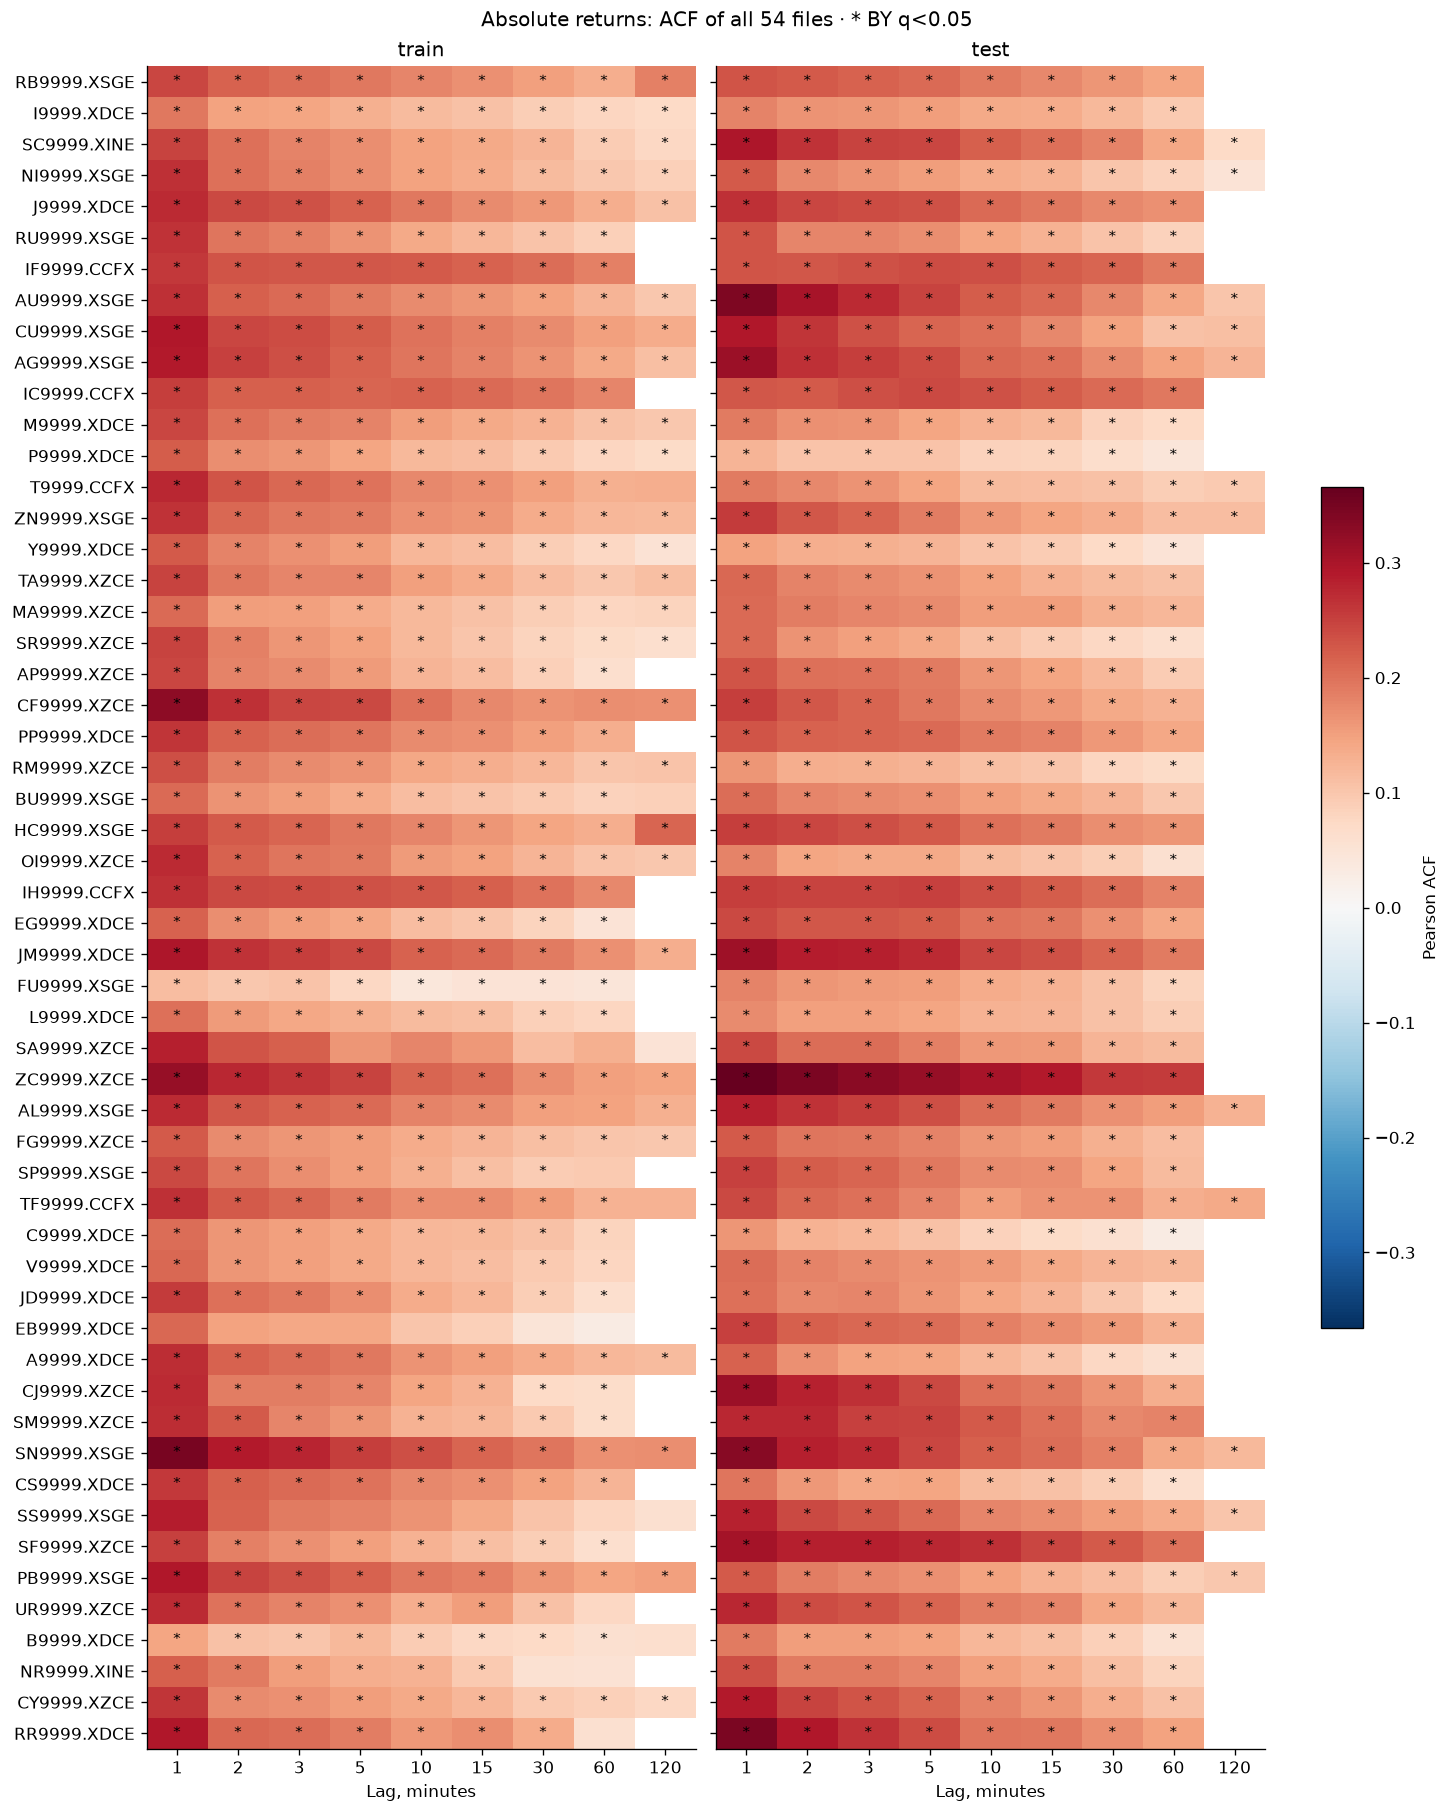

In [7]:
for series,title in [('log_return',"Returns"),('abs_log_return',"Absolute returns")]:
    p=acf.query('series==@series and sample=="all" and period!="full"')
    limit=max(.01,float(p.acf.abs().max()))
    fig,axes=plt.subplots(1,2,figsize=(12,15),sharey=True,layout='constrained')
    for ax,period in zip(axes,['train','test']):
        part=p[p.period==period]
        matrix=part.pivot(index='file',columns='lag',values='acf').reindex(index=files,columns=LAGS)
        q=part.pivot(index='file',columns='lag',values='q_by').reindex(index=files,columns=LAGS)
        im=ax.imshow(matrix,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
        ax.set_xticks(range(len(LAGS)),LAGS); ax.set_yticks(range(54),[Path(f).stem for f in files]); ax.grid(False)
        for row,col in zip(*np.where(q.to_numpy()<.05)): ax.text(col,row,'*',ha='center',va='center',fontsize=9)
        ax.set(title=period,xlabel="Lag, minutes")
    fig.suptitle(f"{title}: ACF of all 54 files · * BY q<0.05")
    fig.colorbar(im,ax=axes,label='Pearson ACF',shrink=.5)
    savefig(fig,'heatmap_'+series)

## Kurtosis and tails

period,files,median_excess,min_excess,max_excess,median_3sigma_ratio,heavier_files
test,54,12.06229,3.11996,1150.40356,5.03725,54
train,54,16.46037,5.08296,1606.24882,5.34421,54


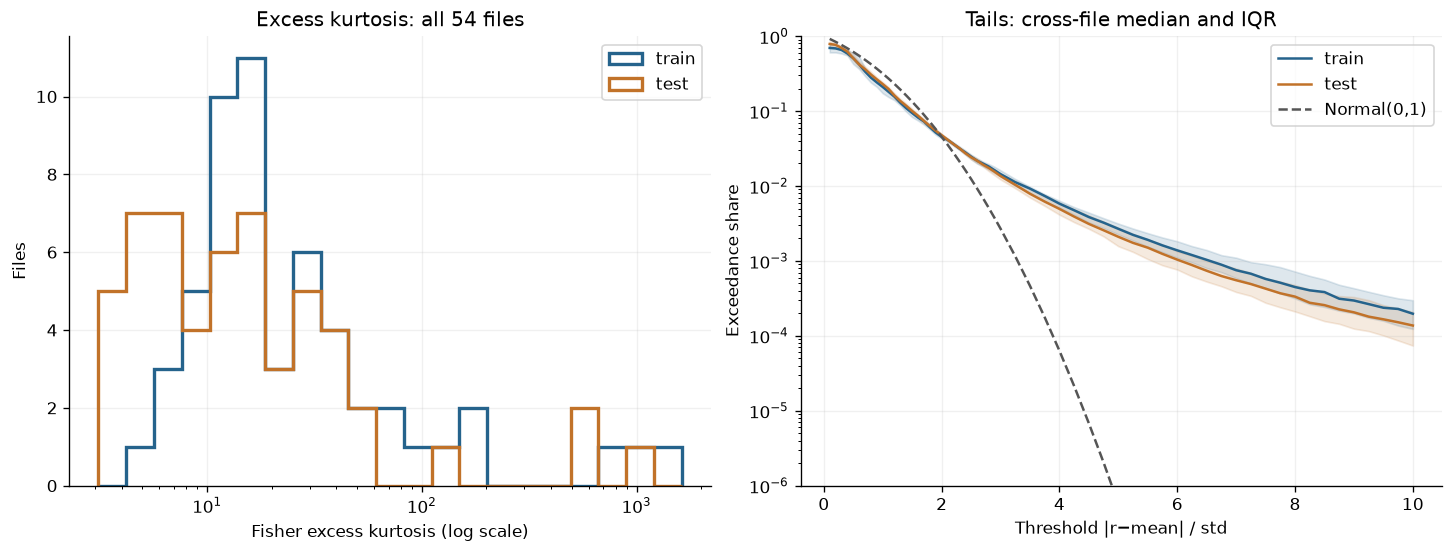

file,period,n,excess_kurtosis,tail_3sigma_vs_gaussian,tail_5sigma_count
B9999.XDCE.csv,train,352123,1606.24882,2.32470,776
NI9999.XSGE.csv,test,181227,1150.40356,4.70696,389
FU9999.XSGE.csv,train,215460,952.81685,1.69676,603
CY9999.XZCE.csv,train,211634,707.29019,4.60123,898
FU9999.XSGE.csv,test,138387,638.04187,4.03355,217
TF9999.CCFX.csv,test,114270,543.60565,4.98856,260
SF9999.XZCE.csv,train,216450,178.29377,6.17930,1009
CF9999.XZCE.csv,train,357282,169.99288,5.28619,1159
TA9999.XZCE.csv,train,357282,137.04289,4.65794,806
EB9999.XDCE.csv,test,138387,127.76207,5.21925,335


Showing 10/108 rows; the complete CSV is saved.


In [8]:
core=tails.query('return_type=="log_return" and volume_group=="all" and period!="full"')
show(core.groupby('period').agg(files=('file','nunique'),median_excess=('excess_kurtosis','median'),min_excess=('excess_kurtosis','min'),
        max_excess=('excess_kurtosis','max'),median_3sigma_ratio=('tail_3sigma_vs_gaussian','median'),
        heavier_files=('tail_label',lambda s:(s=='heavier_than_gaussian').sum())).reset_index(),"Minute log-return tails")
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for period in ['train','test']:
    values=core[core.period==period].excess_kurtosis
    axes[0].hist(values,bins=np.geomspace(max(.01,core.excess_kurtosis.min()),core.excess_kurtosis.max()*1.01,22),histtype='step',lw=2,color=COLORS[period],label=period)
    part=tail_curves.query('period==@period').groupby('threshold_sigma').probability
    x=part.median().index.to_numpy(); y=part.median().to_numpy()
    axes[1].plot(x,np.where(y>0,y,np.nan),color=COLORS[period],label=period)
    axes[1].fill_between(x,part.quantile(.25),part.quantile(.75),alpha=.15,color=COLORS[period])
axes[0].set(xscale='log',xlabel="Fisher excess kurtosis (log scale)",ylabel="Files",title="Excess kurtosis: all 54 files")
axes[1].plot(tail_grid,2*norm.sf(tail_grid),'--',color='#555',label='Normal(0,1)')
axes[1].set(yscale='log',ylim=(1e-6,1),xlabel="Threshold |r−mean| / std",ylabel="Exceedance share",title="Tails: cross-file median and IQR")
for ax in axes: ax.legend()
savefig(fig,'heavy_tails')
show(core.sort_values('excess_kurtosis',ascending=False)[['file','period','n','excess_kurtosis','tail_3sigma_vs_gaussian','tail_5sigma_count']],"Largest excess kurtosis",10)

## Volatility clustering

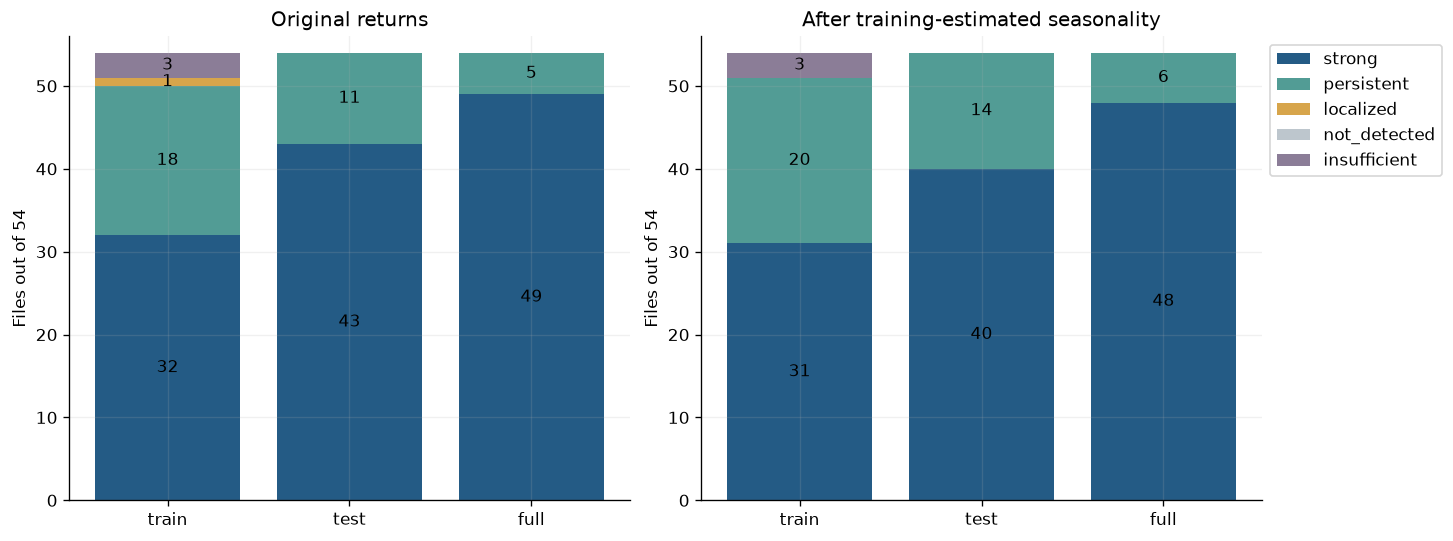

file,classification,acf_5,acf_10,acf_30
RB9999.XSGE.csv,strong,0.20635,0.18929,0.16130
I9999.XDCE.csv,strong,0.15429,0.13903,0.11740
SC9999.XINE.csv,strong,0.24367,0.21773,0.18251
NI9999.XSGE.csv,strong,0.15420,0.13497,0.10185
J9999.XDCE.csv,strong,0.23375,0.20743,0.17718
RU9999.XSGE.csv,strong,0.16880,0.14442,0.10458
IF9999.CCFX.csv,strong,0.23839,0.23708,0.21312
AU9999.XSGE.csv,strong,0.24679,0.22135,0.17502
CU9999.XSGE.csv,strong,0.21367,0.20027,0.14663
AG9999.XSGE.csv,strong,0.23912,0.21079,0.17438


In [9]:
def cluster_class(part):
    p=part.set_index('lag').reindex([5,10,30]); significant=(p.q_by<.05)&(p.acf>0)
    if p.q_by.isna().any(): label='insufficient'
    elif ((p.acf>=.10)&significant).all(): label='strong'
    elif ((p.acf>=.05)&significant).sum()>=2: label='persistent'
    elif significant.any(): label='localized'
    else: label='not_detected'
    return dict(classification=label,mean_acf_5_10_30=p.acf.mean(),**{f'acf_{k}':p.loc[k,'acf'] for k in [5,10,30]})
cluster_rows=[]
for (filename,period,series),p in acf.query('sample=="all" and series in ["abs_log_return","abs_deseasonalized_log_return"]').groupby(['file','period','series'],sort=False):
    cluster_rows.append(dict(file=filename,period=period,series=series,**cluster_class(p)))
clusters=pd.DataFrame(cluster_rows); clusters.to_csv(OUT/'volatility_clustering.csv',index=False)
class_order=['strong','persistent','localized','not_detected','insufficient']
fig,axes=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
for ax,series,title in zip(axes,['abs_log_return','abs_deseasonalized_log_return'],["Original returns","After training-estimated seasonality"]):
    tab=pd.crosstab(clusters.query('series==@series').period,clusters.query('series==@series').classification).reindex(index=PERIODS,columns=class_order,fill_value=0)
    bottom=np.zeros(3)
    for label,color in zip(class_order,['#245b85','#529c95','#d7a54b','#bdc6cd','#8b7d97']):
        values=tab[label].to_numpy(); ax.bar(PERIODS,values,bottom=bottom,label=label,color=color)
        for i,n in enumerate(values):
            if n: ax.text(i,bottom[i]+n/2,str(n),ha='center',va='center')
        bottom+=values
    ax.set(title=title,ylabel="Files out of 54",ylim=(0,56))
axes[1].legend(loc='upper left',bbox_to_anchor=(1,1))
savefig(fig,'clustering_classes')
test_class=clusters.query('period=="test" and series=="abs_log_return"').set_index('file').reindex(files).reset_index()
show(test_class[['file','classification','acf_5','acf_10','acf_30']],"Per-file test classification",54)

## Seasonality and volume

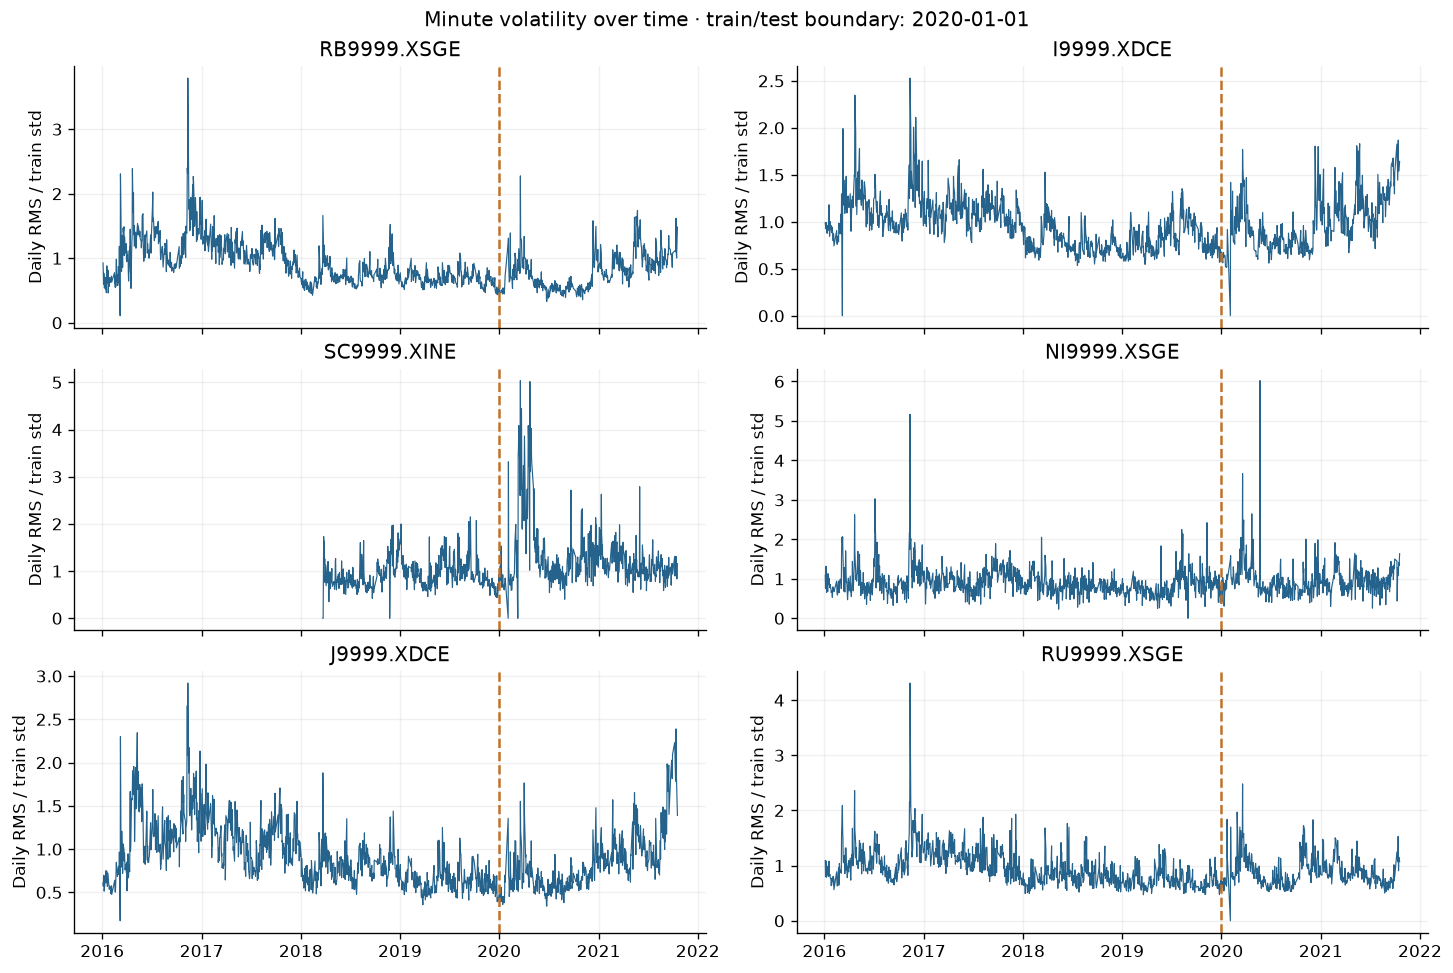

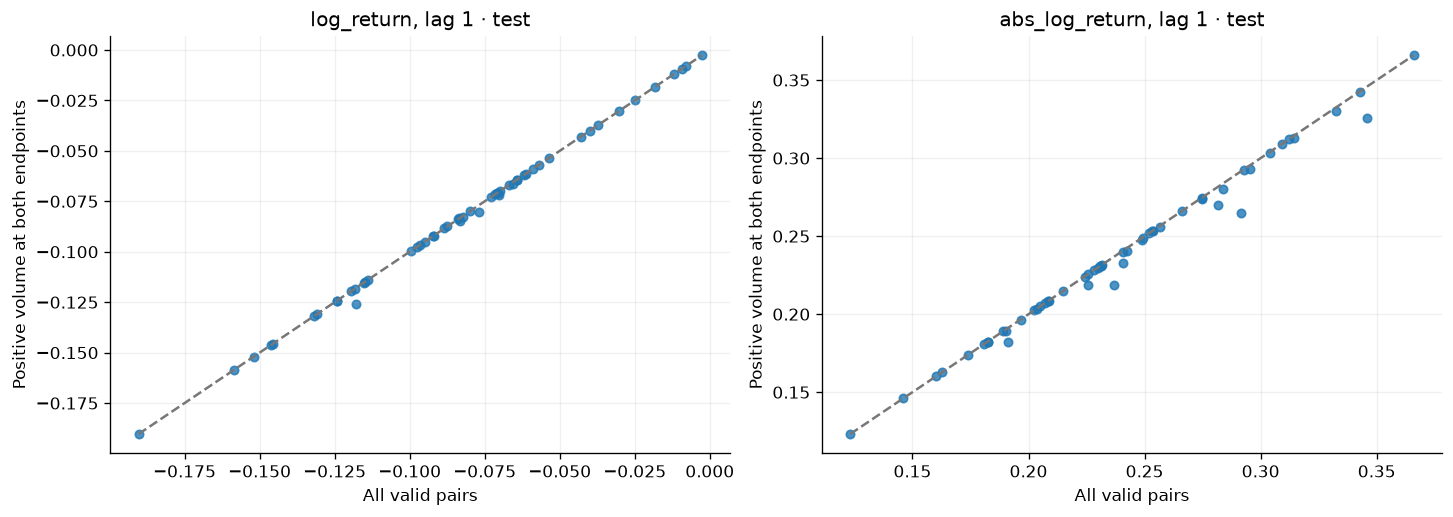

series,lag,pooled_median,segment_mean_median
abs_log_return,1,0.23141,0.07204
abs_log_return,5,0.18855,0.03092
abs_log_return,30,0.13326,0.00068
log_return,1,-0.08113,-0.11240
log_return,5,-0.00118,-0.00944
log_return,30,0.00389,0.00215


In [10]:
fig,axes=plt.subplots(3,2,figsize=(12,8),sharex=True,layout='constrained')
for ax,filename in zip(axes.flat,files[:6]):
    p=daily[daily.file==filename]
    ax.plot(p.day,p.rms/p.train_std,lw=.7,color='#25638c'); ax.axvline(SPLIT,ls='--',color='#c17229')
    ax.set(title=Path(filename).stem,ylabel='Daily RMS / train std')
fig.suptitle("Minute volatility over time · train/test boundary: 2020-01-01")
savefig(fig,'daily_volatility')
fig,axes=plt.subplots(1,2,figsize=(12,4.2),layout='constrained')
for ax,series in zip(axes,['log_return','abs_log_return']):
    p=acf.query('period=="test" and series==@series and lag==1').pivot(index='file',columns='sample',values='acf')
    ax.scatter(p['all'],p.positive_volume_pairs,s=25,alpha=.8)
    low=float(p.min().min()); high=float(p.max().max()); ax.plot([low,high],[low,high],'--',color='#777')
    ax.set(title=f'{series}, lag 1 · test',xlabel="All valid pairs",ylabel="Positive volume at both endpoints")
savefig(fig,'zero_volume_sensitivity')
comparison=acf.query('period=="test" and sample=="all" and lag in [1,5,30] and series in ["log_return","abs_log_return"]').groupby(['series','lag']).agg(pooled_median=('acf','median'),segment_mean_median=('segment_mean','median')).reset_index()
show(comparison,"Different ACF estimands: pooled pairs and equal-segment mean")

## Summary

In [11]:
summary={'files':54,'rows':int(coverage.query('period=="full"').rows.sum()),'start':str(coverage.start.min()),'end':str(coverage.end.max()),
         'train_rows':int(coverage.query('period=="train"').rows.sum()),'test_rows':int(coverage.query('period=="test"').rows.sum()),
         'test_median_return_acf1':float(acf.query('period=="test" and series=="log_return" and lag==1 and sample=="all"').acf.median()),
         'test_median_abs_acf1':float(acf.query('period=="test" and series=="abs_log_return" and lag==1 and sample=="all"').acf.median()),
         'test_median_excess_kurtosis':float(core.query('period=="test"').excess_kurtosis.median()),
         'test_heavier_than_gaussian_files':int(core.query('period=="test"').tail_label.eq('heavier_than_gaussian').sum()),
         'test_clustering_counts':test_class.classification.value_counts().to_dict()}
display(Markdown(f"**Recomputed {summary['files']} files and {summary['rows']:,} bars.** Test median ACF(r,1) = {summary['test_median_return_acf1']:.4f}, "
    f"ACF(|r|,1) = {summary['test_median_abs_acf1']:.4f}; median excess kurtosis = {summary['test_median_excess_kurtosis']:.2f}. "
    f"The descriptive tail rule exceeds the Gaussian benchmark in {summary['test_heavier_than_gaussian_files']}/54 files. Test classes: {summary['test_clustering_counts']}."))
assert digest(CLEAN)==source_hash
assert acf.pairs.ge(0).all() and acf.acf.dropna().between(-1,1).all()
assert len(acf)==54*3*(6*len(LAGS)+6)
manifest=dict(source=str(CLEAN.relative_to(ROOT)),source_sha256=source_hash,universe=str(UNIVERSE.relative_to(ROOT)),universe_sha256=digest(UNIVERSE),
    files=files,requested_start=str(START),train_end_exclusive=str(SPLIT),test_end_exclusive=str(END),observed_end=summary['end'],
    features=feature_records,lags=LAGS,acf_definition='within-segment exact-lag pooled Pearson; equal-segment mean as sensitivity',
    uncertainty='Pearson influence scores aggregated by observed calendar date; max Bartlett HAC SE20/60; >=90 active dates; BY within period',
    observations_deleted=0,backtest_run=False,selection_is_retrospective=True,summary=summary,
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','pyarrow','matplotlib','numba']},python=platform.python_version())
(OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n')
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n')
print("Checks passed. Next: 06_strategies_hypotheses_54.ipynb; no backtest was run here.")

**Recomputed 54 files and 22,738,725 bars.** Test median ACF(r,1) = -0.0811, ACF(|r|,1) = 0.2314; median excess kurtosis = 12.06. The descriptive tail rule exceeds the Gaussian benchmark in 54/54 files. Test classes: {'strong': 43, 'persistent': 11}.

Checks passed. Next: 06_strategies_hypotheses_54.ipynb; no backtest was run here.
